<a href="https://colab.research.google.com/github/HafizRizqi/PCVK_2026/blob/main/Tugas_Kelompok_Week07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum Kelompok — OCR pada Citra KTP

**Modul P7: Segmentasi Citra dengan Thresholding**



## 1. Instalasi Tesseract dan library

Tesseract adalah mesin OCR, sedangkan `pytesseract` menghubungkan Tesseract dengan Python. Model bahasa Indonesia dipasang agar pengenalan teks menggunakan `ind`.

In [3]:
!apt-get update -qq
!apt-get install -y tesseract-ocr tesseract-ocr-ind
!pip install -q pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
tesseract-ocr-ind is already the newest version (1:4.1.0-2).
0 upgraded, 0 newly installed, 0 to remove and 30 not upgraded.


## 2. Import library dan masukkan gambar KTP

Unggah **satu gambar KTP untuk satu kali pengujian**. Untuk memenuhi bagian kerja kelompok, ulangi pengujian dengan citra anggota lain dan gunakan 10 kata acuan yang sesuai dengan gambar tersebut.

Saving ktp_fulan.jpg to ktp_fulan.jpg
Nama file: ktp_fulan.jpg
Ukuran gambar: 694 x 458


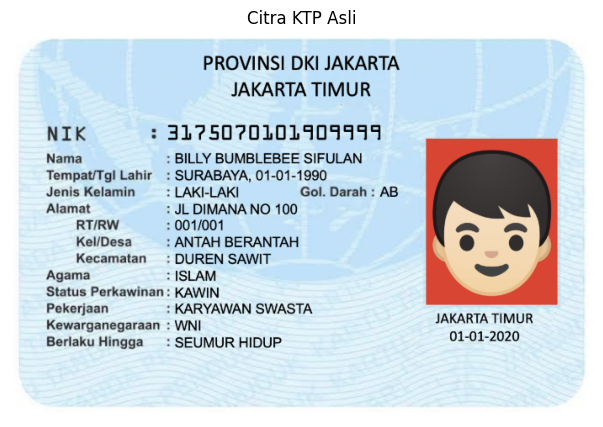

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pytesseract
import re
from pytesseract import Output
from google.colab import files

uploaded = files.upload()
nama_file = list(uploaded.keys())[0]
img = cv2.imread(nama_file)

if img is None:
    raise ValueError("Gambar tidak berhasil dibaca. Periksa kembali file yang diunggah.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print("Nama file:", nama_file)
print("Ukuran gambar:", img.shape[1], "x", img.shape[0])

plt.figure(figsize=(8, 5))
plt.imshow(img_rgb)
plt.title("Citra KTP Asli")
plt.axis("off")
plt.show()

## 3. Membuat hasil segmentasi Otsu dan Adaptive

Ketiga citra menggunakan ukuran yang sama. Otsu menentukan nilai ambang secara otomatis, sedangkan Adaptive Gaussian menghitung ambang lokal berdasarkan lingkungan piksel. Parameter Adaptive mengikuti contoh pada modul: `blockSize=11` dan `C=2`.

Nilai threshold Otsu: 150.0


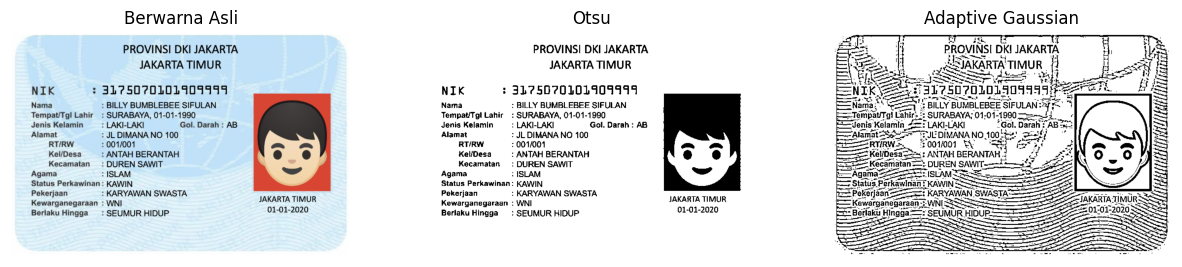

In [5]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

nilai_otsu, citra_otsu = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

citra_adaptive = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 11, 2
)

print("Nilai threshold Otsu:", nilai_otsu)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Berwarna Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(citra_otsu, cmap="gray")
plt.title("Otsu")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(citra_adaptive, cmap="gray")
plt.title("Adaptive Gaussian")
plt.axis("off")
plt.show()

## 4. Membaca teks dari ketiga citra

Agar perbandingan adil, bahasa (`ind`) dan konfigurasi `--psm 6` dibuat sama untuk ketiga citra.

In [6]:
konfigurasi = "--psm 6"

teks_warna = pytesseract.image_to_string(img_rgb, lang="ind", config=konfigurasi)
teks_otsu = pytesseract.image_to_string(citra_otsu, lang="ind", config=konfigurasi)
teks_adaptive = pytesseract.image_to_string(citra_adaptive, lang="ind", config=konfigurasi)

print("===== OCR CITRA BERWARNA =====")
print(teks_warna)
print("===== OCR HASIL OTSU =====")
print(teks_otsu)
print("===== OCR HASIL ADAPTIVE =====")
print(teks_adaptive)

===== OCR CITRA BERWARNA =====
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31750?0101901411
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT t
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI SIata TOR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

===== OCR HASIL OTSU =====
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 32?5D?0101401111
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW :001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga: SEUMUR HIDUP 01-01-2020

===== OCR HASIL ADAPTIVE =====
sr (7 bg pr Ka it 3
“5 | PROVINSI DKI JAKARTA Eh 1
ea SSJAKARTA TIMUR | Ta!

Sm

## 5. Menampilkan kotak hijau pada teks yang dikenali

`image_to_data()` memberikan posisi kata dan nilai confidence. kotak hijau hanya ditampilkan pada teks dengan **confidence lebih dari 60**.

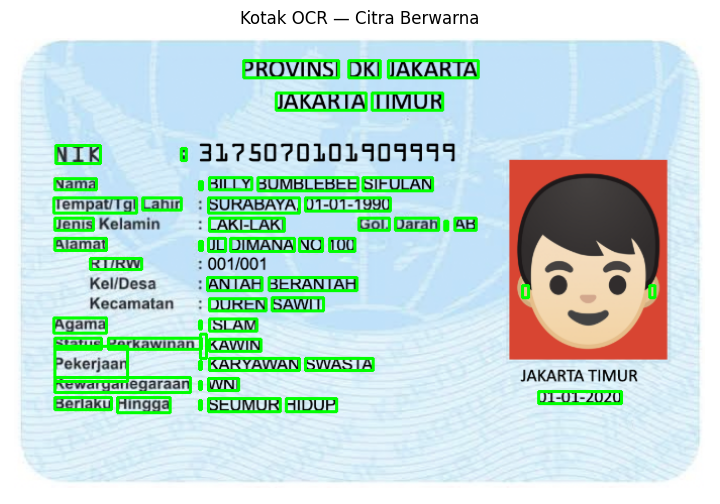

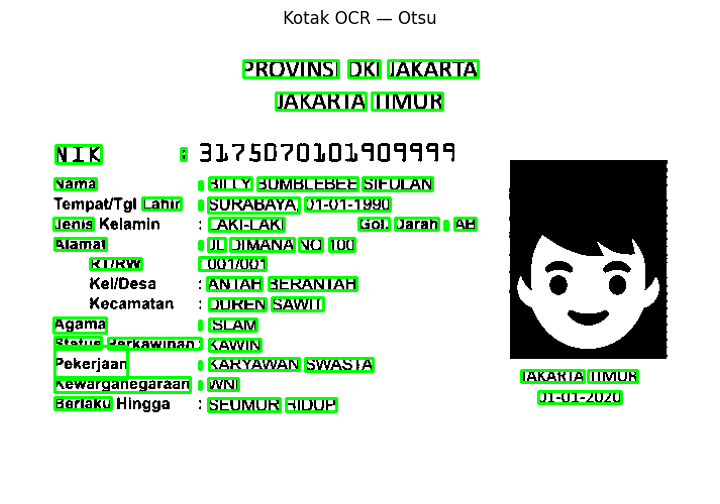

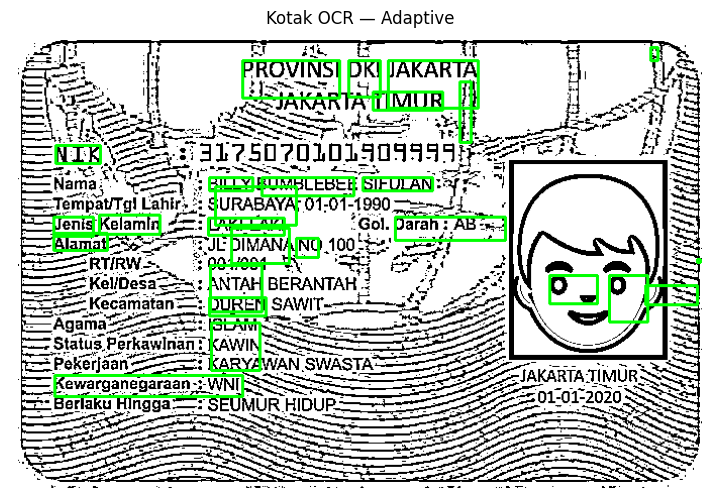

In [7]:
def tampilkan_kotak(gambar, judul):
    data = pytesseract.image_to_data(
        gambar, lang="ind", config=konfigurasi,
        output_type=Output.DICT
    )

    if len(gambar.shape) == 2:
        hasil = cv2.cvtColor(gambar, cv2.COLOR_GRAY2RGB)
    else:
        hasil = gambar.copy()

    for i in range(len(data["text"])):
        kata = data["text"][i].strip()
        conf = float(data["conf"][i])

        if kata != "" and conf > 60:
            x = data["left"][i]
            y = data["top"][i]
            w = data["width"][i]
            h = data["height"][i]
            cv2.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)

    plt.figure(figsize=(10, 6))
    plt.imshow(hasil, cmap="gray" if len(gambar.shape) == 2 else None)
    plt.title(judul)
    plt.axis("off")
    plt.show()


tampilkan_kotak(img_rgb, "Kotak OCR — Citra Berwarna")
tampilkan_kotak(citra_otsu, "Kotak OCR — Otsu")
tampilkan_kotak(citra_adaptive, "Kotak OCR — Adaptive")

## 6. Menentukan 10 kata acuan dan menghitung kecocokan

Daftar berikut cocok untuk gambar contoh `ktp_fulan.jpg`. Jika menggunakan KTP anggota lain, ubah 10 kata di bawah menjadi kata atau angka yang jelas terlihat pada gambar tersebut.

Sebuah item dinyatakan cocok hanya jika seluruh huruf pada kata acuan ditemukan sebagai satu kata OCR. Perbedaan huruf besar-kecil dan tanda baca di sekitar kata diabaikan.

In [8]:
teks_acuan = [
    "PROVINSI", "JAKARTA", "TIMUR", "BILLY", "BUMBLEBEE",
    "SIFULAN", "SURABAYA", "ISLAM", "KAWIN", "SWASTA"
]

hasil_teks = {
    "Citra berwarna": teks_warna,
    "Otsu": teks_otsu,
    "Adaptive": teks_adaptive
}

def daftar_kata(teks):
    return re.findall(r"[A-Z0-9]+", teks.upper())

kata_ocr = {nama: daftar_kata(teks) for nama, teks in hasil_teks.items()}

baris_tabel = []
for acuan in teks_acuan:
    baris = {"Teks sebenarnya": acuan}
    for nama in hasil_teks:
        if acuan in kata_ocr[nama]:
            baris[nama] = acuan
        else:
            baris[nama] = "Tidak cocok / periksa OCR"
    baris_tabel.append(baris)

tabel_kecocokan = pd.DataFrame(baris_tabel)
tabel_kecocokan

,Teks sebenarnya,Citra berwarna,Otsu,Adaptive
0,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,TIMUR,TIMUR,TIMUR,TIMUR
3,BILLY,BILLY,BILLY,BILLY
4,BUMBLEBEE,BUMBLEBEE,BUMBLEBEE,BUMBLEBEE
5,SIFULAN,SIFULAN,SIFULAN,SIFULAN
6,SURABAYA,SURABAYA,SURABAYA,SURABAYA
7,ISLAM,ISLAM,ISLAM,Tidak cocok / periksa OCR
8,KAWIN,KAWIN,KAWIN,KAWIN
9,SWASTA,SWASTA,SWASTA,Tidak cocok / periksa OCR


**Catatan pengisian tabel laporan:** jika satu item tidak cocok, lihat teks OCR lengkap di bagian 4. Bila Tesseract membaca kata tersebut sebagai kata lain, ganti isi sel `Tidak cocok / periksa OCR` dengan hasil salah baca yang benar-benar muncul. Jika tidak ada hasilnya, tulis `Tidak terbaca`. Dengan begitu, tabel laporan mencatat hasil eksperimen yang sebenarnya.

## 7. Menghitung persentase kecocokan dan rata-rata confidence

Rumus kecocokan:

\[
	ext{Kecocokan (\%)} = rac{	ext{jumlah item yang terbaca tepat}}{10} 	imes 100
\]

Rata-rata confidence dihitung dari kata yang memiliki teks dan nilai confidence valid. Nilai confidence bukan persentase kecocokan; keduanya perlu dibandingkan.

In [9]:
def hitung_confidence(gambar):
    data = pytesseract.image_to_data(
        gambar, lang="ind", config=konfigurasi,
        output_type=Output.DICT
    )
    nilai_conf = []

    for kata, conf in zip(data["text"], data["conf"]):
        if kata.strip() != "" and float(conf) >= 0:
            nilai_conf.append(float(conf))

    if len(nilai_conf) == 0:
        return 0
    return np.mean(nilai_conf)

citra_uji = {
    "Berwarna asli": (img_rgb, teks_warna),
    "Segmentasi Otsu": (citra_otsu, teks_otsu),
    "Segmentasi Adaptive": (citra_adaptive, teks_adaptive)
}

ringkasan = []
for nama, (gambar, teks) in citra_uji.items():
    kata = daftar_kata(teks)
    tepat = sum(1 for acuan in teks_acuan if acuan in kata)
    kecocokan = tepat / len(teks_acuan) * 100
    confidence = hitung_confidence(gambar)

    ringkasan.append({
        "Citra masukan OCR": nama,
        "Item terbaca tepat": f"{tepat}/{len(teks_acuan)}",
        "Kecocokan (%)": round(kecocokan, 2),
        "Rata-rata confidence": round(confidence, 2)
    })

tabel_ringkasan = pd.DataFrame(ringkasan)
tabel_ringkasan

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10/10,100.0,77.48
1,Segmentasi Otsu,10/10,100.0,81.47
2,Segmentasi Adaptive,8/10,80.0,31.91


## 8. Panduan menjawab pertanyaan analisis

Gunakan angka pada tabel ringkasan dan teks OCR yang tampil di atas. Jangan mengisi jawaban berdasarkan perkiraan jika hasil percobaan menunjukkan hal lain.

In [ ]:
nilai_akurasi = tabel_ringkasan["Kecocokan (%)"].max()
metode_tertepat = tabel_ringkasan.loc[
    tabel_ringkasan["Kecocokan (%)"] == nilai_akurasi,
    "Citra masukan OCR"
].tolist()

nilai_confidence = tabel_ringkasan["Rata-rata confidence"].max()
metode_confidence = tabel_ringkasan.loc[
    tabel_ringkasan["Rata-rata confidence"] == nilai_confidence,
    "Citra masukan OCR"
].tolist()

print("1. Kecocokan tertinggi:", ", ".join(metode_tertepat),
      "dengan kecocokan", nilai_akurasi, "%.")
print("2. Periksa tabel perbandingan dan teks OCR lengkap untuk mencatat minimal dua salah baca.")
print("3. Bandingkan nilai kecocokan ketiga metode. Segmentasi tidak selalu meningkatkan hasil OCR.")
print("4. Pola dan warna latar dapat mengurangi kontras tulisan. Thresholding dapat membantu,")
print("   tetapi jika detail huruf hilang atau muncul banyak bintik, OCR justru dapat memburuk.")
print("5. Confidence tertinggi:", ", ".join(metode_confidence),
      "dengan rata-rata", nilai_confidence, ". Bandingkan apakah metode ini juga memiliki kecocokan tertinggi.")

### Contoh kerangka jawaban laporan

1. **Citra paling tepat:** sebutkan metode dengan kecocokan tertinggi dan cantumkan jumlah item yang benar dari 10 item berdasarkan tabel ringkasan.
2. **Kesalahan pembacaan:** tuliskan minimal dua contoh dari output OCR, misalnya angka yang berubah, huruf tertukar, atau kata yang tidak terbaca. Gunakan hasil yang benar-benar muncul di notebook.
3. **Pengaruh segmentasi:** jelaskan apakah nilai kecocokan Otsu dan Adaptive lebih tinggi atau lebih rendah dibanding citra berwarna pada percobaan ini. Segmentasi tidak selalu meningkatkan akurasi karena sebagian detail karakter dapat hilang.
4. **Pengaruh latar:** latar berwarna atau berpola dapat membuat perbedaan antara tulisan dan latar kurang jelas. Otsu menggunakan satu ambang untuk seluruh citra, sedangkan Adaptive memakai ambang lokal; hasil akhirnya bergantung pada citra.
5. **Confidence dan kecocokan:** bandingkan baris dengan confidence tertinggi terhadap baris dengan kecocokan tertinggi. Confidence yang tinggi tidak otomatis berarti semua kata benar.

**Catatan untuk kerja kelompok:** jalankan pengujian untuk citra tiap anggota, simpan tabel dan gambar hasil kotak OCR, kemudian rangkum hasilnya dalam laporan kelompok. Gunakan gambar yang diizinkan untuk tugas dan tutupi data pribadi yang tidak diperlukan.